#**<font color="00E5FF"> Aprendizaje por refuerzo: reposición de un producto perecedero**</font>

**<font color="BDC3C7">Q-Learning · SARSA · Programación dinámica (Value Iteration) como referencia óptima**

---



- **<font color="BDC3C7">Elaborado por:** </font>Brayan Yesid Vega Niño ·
- **<font color="BDC3C7">Fecha:** </font>18 de noviembre de 2026
- **<font color="BDC3C7">Curso:** </font>CADI - Introducción a Machine Learning
- **<font color="BDC3C7">Caso:** </font>Tarea de Reinforcement Learning (Semana 14): un agente aprende cuántas unidades pedir cada día para una panadería de barrio con producto perecedero y demanda estocástica.
- **<font color="BDC3C7">Algoritmos:** </font>Q-Learning (fuera de política) · SARSA (dentro de la política) · Value Iteration (solución exacta, solo como referencia).
- **<font color="BDC3C7">Repositorio:** </font>https://github.com/bravegn-arch/Semana_14_Reinforcement_Learning


##**<font color="BB86FC">Contenido** </n> <font color=#FFFFFF>


- Sección 0 · Preparación del entorno de trabajo
- Sección 1 · Análisis del problema
- Sección 2 · Diseño de la solución
- Sección 3 · Implementación en Python
- Sección 4 · Análisis de resultados
- Sección 5 · Conclusiones
- Sección 6 · Referencias

---

---

<a id="seccion-0"></a>
##**<font color="BB86FC">Sección 0 · Preparación del entorno de trabajo**

**<font color="2ECC71">Preparación de entorno:</font>** Se cargan las librerías, se fija la **semilla global** (`SEED = 42`) y se definen las carpetas donde el cuaderno guarda las figuras (`/figures`) y los datos de ejemplo (`/data`). Todo el código usa solo **NumPy, SciPy, pandas y Matplotlib** (no se necesita instalar nada en Google Colab). La variable `RAPIDO` reduce el presupuesto de entrenamiento para probar el cuaderno en cerca de un minuto; con `RAPIDO = False` se reproducen los resultados del informe.

---

In [ ]:
# Librerías base
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson
import warnings
warnings.filterwarnings("ignore")

# Opciones de visualización
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# Reproducibilidad: una única semilla base para todo el cuaderno
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Carpetas de salida: el cuaderno vive en /notebooks; figuras y datos en la raíz del repositorio
BASE = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
FIG_DIR = os.path.join(BASE, "figures")
DATA_DIR = os.path.join(BASE, "data")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

# Paleta fija para identificar los algoritmos en todas las gráficas
COLORES = ["teal", "salmon", "#8064A2", "goldenrod", "skyblue", "seagreen", "tomato", "slategray"]

# Presupuesto de cómputo. Con RAPIDO = True el cuaderno corre en ~1 minuto (resultados menos precisos).
RAPIDO = False
EPISODIOS         = 20_000 if RAPIDO else 100_000   # episodios de entrenamiento (comparación principal)
SEMILLAS          = [0, 1] if RAPIDO else [0, 1, 2, 3, 4]
EPISODIOS_BARRIDO = 10_000 if RAPIDO else 50_000    # episodios por configuración en los barridos
SEMILLAS_BARRIDO  = [0, 1] if RAPIDO else [0, 1, 2]
print(f"RAPIDO = {RAPIDO} | episodios = {EPISODIOS:,} | semillas = {SEMILLAS}")

RAPIDO = False | episodios = 100,000 | semillas = [0, 1, 2, 3, 4]


### <font color="2ECC71">0.1 Funciones comunes

>**<font color="BDC3C7">Nota:</font>** `guardar_figura` guarda cada gráfica en `/figures` para el informe. `pct_optimo` expresa qué porción de la brecha entre una política de referencia mala (aleatoria) y la política óptima cubre cada método, lo que facilita comparar sin depender de la escala monetaria.

In [ ]:
def guardar_figura(nombre):
    """Guarda la figura activa en /figures (PNG, 200 dpi) para usarla en el informe."""
    plt.savefig(os.path.join(FIG_DIR, nombre + ".png"), dpi=200, bbox_inches="tight")


def pct_optimo(valor, optimo, referencia):
    """Porcentaje de la brecha 'referencia -> óptimo' que cubre un método (0 % = referencia, 100 % = óptimo)."""
    return 100 * (valor - referencia) / (optimo - referencia)

---
<a id="seccion-1"></a>
##**<font color="BB86FC">Sección 1 · Análisis del problema**

**<font color="2ECC71">Objetivo:</font>** Describir el problema de decisión, identificar el objetivo del agente, las condiciones del entorno y los resultados esperados, antes de elegir el algoritmo.

---

### <font color="2ECC71">1.1 Descripción del problema, objetivo y resultados esperados

**<font color="2ECC71">El problema.</font>** Una panadería de barrio en Bogotá vende un producto **perecedero** (por ejemplo, canastas de pan artesanal) que **dura 3 días**: llega fresco, y si no se vende queda a un día de vencer y luego a cero días. Cada mañana el administrador decide **cuántas unidades pedir** (de 0 a 7). La **demanda es aleatoria** y **cambia con el día de la semana** (fines de semana altos, comienzo de semana bajo). Pedir de menos pierde ventas y clientes; pedir de más genera **merma** (producto desechado).

**<font color="2ECC71">Objetivo del agente.</font>** Maximizar la **ganancia acumulada** (ventas menos costo de compra, merma y faltantes) en el largo plazo. Es un problema de **decisión secuencial bajo incertidumbre**: lo que se pide hoy determina el inventario que hay mañana, y por eso no puede resolverse día por día de forma aislada.

**<font color="2ECC71">Condiciones del entorno.</font>**

- La demanda de cada día es **independiente** y sigue una **distribución de Poisson** con media distinta por día de la semana.
- El pedido llega **de inmediato** (sin plazo de entrega) y se vende primero lo **más viejo** (FIFO).
- Lo que vence se **desecha** al cierre; el inventario se renueva solo mediante pedidos.
- El agente **no conoce** las probabilidades de la demanda: tiene que aprenderlas **interactuando** con el entorno (se simula la operación de la tienda).
- Un episodio equivale a **28 días** (4 semanas) empezando sin inventario.

**<font color="2ECC71">Resultados esperados.</font>** (1) Que el agente aprenda una **política de pedidos que dependa del día y del inventario** y supere a las reglas simples que usaría un administrador; (2) que se acerque a la **política óptima**, que aquí sí se puede calcular de forma exacta (porque el problema es pequeño) y sirve de **techo de comparación**; (3) entender cómo influyen los hiperparámetros en el aprendizaje.

>**<font color="BDC3C7">Nota sobre los datos:</font>** el problema es **simulado**: los parámetros (demanda media por día, precio y costos) son **supuestos razonables del caso**, no datos medidos de una tienda real, por lo que no se usó ningún conjunto de datos abiertos. El entorno está parametrizado para poder **calibrarlo con datos reales** (por ejemplo, ventas diarias de un negocio o datos abiertos de comercio) sin cambiar el código del agente.

### <font color="2ECC71">1.2 Parámetros del caso y demanda semanal

>**<font color="BDC3C7">Nota:</font>** Montos en **miles de pesos colombianos por unidad**. Se vende a **4,0**, se compra a **2,5** (margen de **1,5** por unidad vendida), cada unidad que se desecha cuesta **0,5** adicional por disposición y cada unidad de demanda no atendida resta **0,5** por pérdida de clientes. La capacidad máxima es de 7 unidades por pedido y por "edad" de inventario.

In [ ]:
# Parámetros del problema (supuestos del caso, en miles de pesos colombianos por unidad)
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
DEMANDA_MEDIA = np.array([2.0, 2.0, 2.5, 3.0, 4.0, 5.0, 3.0])   # unidades/día (Poisson)
CAP = 7                                  # máximo de unidades en cada "edad" y por pedido
PRECIO, COSTO, MERMA, FALTANTE = 4.0, 2.5, 0.5, 0.5
VIDA_UTIL = 3                            # días que dura el producto (llega fresco, queda a 1 y a 0 días de vencer)
H = 28                                   # días por episodio (4 semanas)
GAMMA = 0.95                             # factor de descuento
NA = CAP + 1                             # acciones: pedir 0..CAP unidades
N_ESTADOS = 7 * NA * NA                  # (día de la semana) x (unidades que vencen mañana) x (unidades que vencen hoy)

params = pd.DataFrame({
    "Demanda media (unid./día)": DEMANDA_MEDIA,
    "P(demanda > CAP)": poisson.sf(CAP, DEMANDA_MEDIA),
    "Cuantil 90 de la demanda": poisson.ppf(0.90, DEMANDA_MEDIA),
}, index=DIAS)
print("Margen por unidad vendida     :", PRECIO - COSTO)
print("Pérdida por unidad sobrante   :", COSTO + MERMA, "(costo no recuperado + disposición)")
print("Pérdida por unidad faltante   :", FALTANTE, "(+ margen no ganado de", PRECIO - COSTO, ")")
print("Estados:", N_ESTADOS, "| Acciones:", NA, "| Pares estado-acción:", N_ESTADOS * NA)

# Datos de ejemplo para el repositorio: parámetros y un año de demanda simulada
params.to_csv(os.path.join(DATA_DIR, "parametros_demanda.csv"), index_label="dia")
rng_demo = np.random.default_rng(SEED)
dias_365 = np.arange(365) % 7
pd.DataFrame({"dia_semana": [DIAS[i] for i in dias_365],
              "demanda": rng_demo.poisson(DEMANDA_MEDIA[dias_365])}).to_csv(
    os.path.join(DATA_DIR, "demanda_simulada_365d.csv"), index_label="dia_n")
params.round(3)

Margen por unidad vendida     : 1.5
Pérdida por unidad sobrante   : 3.0 (costo no recuperado + disposición)
Pérdida por unidad faltante   : 0.5 (+ margen no ganado de 1.5 )
Estados: 448 | Acciones: 8 | Pares estado-acción: 3584


,Demanda media (unid./día),P(demanda > CAP),Cuantil 90 de la demanda
Lunes,2.0,0.001,4.0
Martes,2.0,0.001,4.0
Miércoles,2.5,0.004,5.0
Jueves,3.0,0.012,5.0
Viernes,4.0,0.051,7.0
Sábado,5.0,0.133,8.0
Domingo,3.0,0.012,5.0


**<font color="2ECC71">Interpretación 1.2:</font>**

- **Estacionalidad:** la demanda media va de **2,0 unidades** (lunes y martes) a **5,0** (sábado), con un segundo pico el viernes (4,0). Una política que pida lo mismo todos los días tiene que equivocarse alguno de ellos.
- **Capacidad:** el sábado la demanda puede superar la capacidad de 7 unidades con una probabilidad de **13,3 %** y el viernes con **5,1 %**; el resto de días es prácticamente irrelevante.
- **Asimetría de costos:** pasarse cuesta **3,0** por unidad (costo no recuperado más disposición) y quedarse corto cuesta **2,0** (margen no ganado más penalización), así que conviene un **inventario algo inferior a la mediana de la demanda**.
- **Tamaño del problema:** hay **448 estados** (7 días × 8 × 8 niveles de inventario) y **8 acciones**, es decir, **3.584 pares estado-acción**: suficientemente pequeño para usar **tablas** (RL tabular) y para resolverlo de forma exacta como referencia.

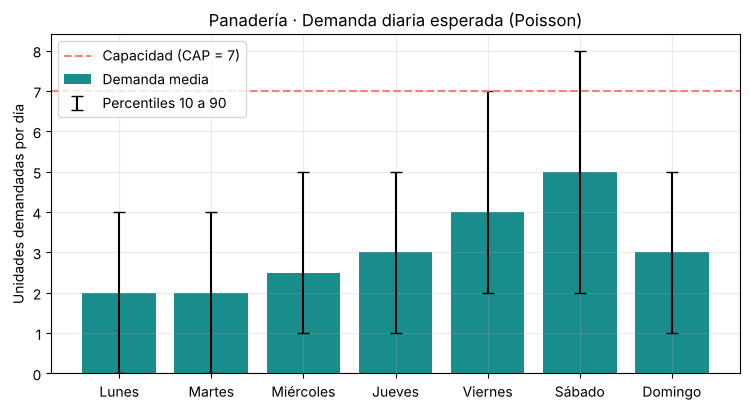

In [ ]:
# Demanda semanal: media y rango entre los percentiles 10 y 90
p10 = poisson.ppf(0.10, DEMANDA_MEDIA)
p90 = poisson.ppf(0.90, DEMANDA_MEDIA)

fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.bar(DIAS, DEMANDA_MEDIA, color="teal", alpha=0.9, label="Demanda media")
ax.errorbar(DIAS, DEMANDA_MEDIA, yerr=[DEMANDA_MEDIA - p10, p90 - DEMANDA_MEDIA], fmt="none",
            ecolor="black", capsize=4, label="Percentiles 10 a 90")
ax.axhline(CAP, color="salmon", ls="--", label=f"Capacidad (CAP = {CAP})")
ax.set_ylabel("Unidades demandadas por día")
ax.set_title("Panadería · Demanda diaria esperada (Poisson)")
ax.legend()
plt.tight_layout()
guardar_figura("fig1_demanda_semanal")
plt.show()

**<font color="2ECC71">Interpretación de la figura 1.2:</font>** Las barras muestran la demanda media y las líneas el rango entre los percentiles 10 y 90, que es amplio (por ejemplo, de 2 a 8 unidades el sábado). Esta **incertidumbre alta** es lo que hace que el inventario de seguridad valga la pena, pero también lo que provoca la merma.

### <font color="2ECC71">1.3 Referencia teórica de un solo día (problema del vendedor de periódicos)

>**<font color="BDC3C7">Nota:</font>** Si no existiera la posibilidad de vender mañana lo que sobra hoy, el problema de cada día tendría solución conocida: completar el inventario hasta el **cuantil crítico** de la demanda, con razón crítica = costo de quedarse corto / (costo de quedarse corto + costo de pasarse). Esta regla se usará más adelante como **política de referencia**.

In [ ]:
# Referencia de un solo día ("problema del vendedor de periódicos"): ignora que lo no vendido se puede vender mañana
num = (PRECIO - COSTO) + FALTANTE          # costo de quedarse corto (cu)
den = num + (COSTO + MERMA)                # cu + costo de pasarse (co)
RC = num / den                             # razón crítica
q_crit = poisson.ppf(RC, DEMANDA_MEDIA).astype(int)
print(f"Razón crítica = {num:.1f} / {den:.1f} = {RC:.2f}")
pd.DataFrame({"Demanda media": DEMANDA_MEDIA, "Inventario objetivo (cuantil crítico)": q_crit}, index=DIAS)

Razón crítica = 2.0 / 5.0 = 0.40


,Demanda media,Inventario objetivo (cuantil crítico)
Lunes,2.0,1
Martes,2.0,1
Miércoles,2.5,2
Jueves,3.0,2
Viernes,4.0,3
Sábado,5.0,4
Domingo,3.0,2


**<font color="2ECC71">Interpretación 1.3:</font>** La razón crítica es **0,40**, así que la regla de un solo día sugiere inventarios objetivo de apenas **1 a 4 unidades** (de 1 el lunes a 4 el sábado). Es una regla **demasiado conservadora** para este caso, porque ignora que el producto dura tres días y que lo que sobra hoy todavía se puede vender mañana. Se espera, por tanto, que tenga un desempeño bajo; en la sección 3.4 se verifica.

---
<a id="seccion-2"></a>
##**<font color="BB86FC">Sección 2 · Diseño de la solución**

**<font color="2ECC71">Objetivo:</font>** Formular el problema como un **Proceso de Decisión de Markov (MDP)**, definir sus componentes (agente, entorno, estados, acciones y recompensas) y justificar el algoritmo.

---

### <font color="2ECC71">2.1 Componentes del aprendizaje por refuerzo

| Componente | Definición en este problema |
|---|---|
| **Agente** | El administrador virtual de la panadería: cada mañana elige cuánto pedir según el día y el inventario. |
| **Entorno** | La tienda: genera la demanda aleatoria, vende, desecha lo vencido y envejece el inventario (clase `PanaderiaEnv`). |
| **Estado** `s = (d, u1, u2)` | `d` = día de la semana (0 a 6); `u1` = unidades que **vencen mañana** (0 a 7); `u2` = unidades que **vencen hoy** (0 a 7). Son **448 estados**. El inventario recién pedido no forma parte del estado porque se decide después de observarlo. |
| **Acción** `a` | Unidades a pedir: `a ∈ {0, 1, …, 7}` (8 acciones). |
| **Recompensa** | `4,0 · ventas − 2,5 · pedido − 0,5 · merma − 0,5 · faltante` (miles de COP del día). |
| **Transición** | Estocástica: depende de la demanda `D ~ Poisson(μ_d)`. El día avanza de forma determinista (lunes → martes → …). |
| **Episodio** | 28 días desde inventario vacío; termina por **límite de tiempo**, no por un estado terminal. |
| **Descuento** | `γ = 0,95`: una ganancia de mañana vale 95 % de la de hoy. |

>**<font color="BDC3C7">¿Por qué el estado es suficiente?</font>** El estado contiene todo lo que determina el futuro: el día (la demanda de mañana depende de él) y cuánto inventario hay de cada edad (determina lo que se puede vender y lo que se va a perder). Por eso el problema cumple la **propiedad de Markov**.

### <font color="2ECC71">2.2 Algoritmo seleccionado y justificación

- **Algoritmo principal: Q-Learning tabular** (Watkins & Dayan, 1992), con política **ε-voraz**. Se elige porque (1) el espacio de estados y acciones es **discreto y pequeño**, de modo que una tabla `Q(s, a)` basta y es interpretable; (2) **no necesita el modelo** de la demanda, que es justo lo que el administrador no conoce; y (3) es **fuera de política**: aprende el valor de la política voraz aunque explore, lo que lo hace eficiente en datos.
- **Comparación: SARSA** (Rummery & Niranjan, 1994). Usa la misma tabla y los mismos hiperparámetros, pero actualiza con la acción **realmente elegida** (incluida la exploración). Permite ver cómo cambia el aprendizaje entre un método fuera de política y uno dentro de la política.
- **Referencia: Value Iteration** (Bellman, 1957). Como aquí el modelo sí puede calcularse, la **política óptima exacta** actúa como "regla de oro": mide qué tan cerca llega el aprendizaje. **El agente nunca la usa para aprender.**
- **Descartados:** los métodos con redes neuronales (DQN) no se justifican con 448 estados; los métodos de política directa (REINFORCE, actor-crítico) añaden complejidad sin beneficio en un espacio tan pequeño.
- **Ecuación de actualización de Q-Learning:** `Q(s,a) ← Q(s,a) + α [ r + γ · max_a' Q(s',a') − Q(s,a) ]`; en SARSA el máximo se reemplaza por `Q(s', a')` con `a'` la acción elegida.

### <font color="2ECC71">2.3 Implementación del entorno

>**<font color="BDC3C7">Nota:</font>** El entorno sigue la interfaz habitual de **Gymnasium** (`reset()` y `step(a)` que devuelve estado, recompensa, `terminated`, `truncated` e `info`), pero se programa en NumPy para no depender de librerías externas. El fin de los 28 días se señala con `truncated = True` (límite de tiempo), no con `terminated`.

In [ ]:
class PanaderiaEnv:
    """Entorno de reposición de un producto perecedero (API tipo Gymnasium, sin dependencias externas).

    Estado    : (día de la semana d, u1, u2) codificado como un entero 0..N_ESTADOS-1.
                u1 = unidades que vencen mañana, u2 = unidades que vencen hoy (se venden primero).
    Acción    : a in {0..CAP}, unidades que se piden al iniciar el día (llegan frescas de inmediato).
    Dinámica  : demanda D ~ Poisson(media del día); se vende primero lo más viejo (FIFO);
                al cerrar, lo que queda de u2 se desecha y el resto envejece un día.
    Recompensa: PRECIO*ventas - COSTO*pedido - MERMA*desechadas - FALTANTE*demanda_no_atendida.
    Episodio  : H días; termina por límite de tiempo (truncated = True), nunca por un estado terminal.
    """
    def __init__(self, seed=None, horizonte=H):
        self.rng = np.random.default_rng(seed)
        self.H = horizonte
        self.n_estados, self.n_acciones = N_ESTADOS, NA

    @staticmethod
    def codificar(d, u1, u2):
        return (d * NA + u1) * NA + u2

    @staticmethod
    def decodificar(s):
        return s // (NA * NA), (s // NA) % NA, s % NA

    def reset(self, dia=None):
        self.d = int(self.rng.integers(7)) if dia is None else dia
        self.u1 = self.u2 = 0                      # se arranca sin inventario
        self.t = 0
        # Demanda de todo el episodio, muestreada de una vez (más rápido que muestrear paso a paso)
        self._dem = self.rng.poisson(DEMANDA_MEDIA[(self.d + np.arange(self.H)) % 7]).tolist()
        return self.codificar(self.d, self.u1, self.u2)

    def step(self, a):
        D = self._dem[self.t]
        v2 = min(self.u2, D); r = D - v2           # se vende primero lo que vence hoy
        v1 = min(self.u1, r); r -= v1              # luego lo que vence mañana
        v0 = min(a, r);       falt = r - v0        # por último lo recién pedido
        merma = self.u2 - v2                       # lo que vence hoy sin vender se desecha
        recompensa = PRECIO * (v2 + v1 + v0) - COSTO * a - MERMA * merma - FALTANTE * falt
        self.u2, self.u1 = self.u1 - v1, a - v0    # el inventario envejece un día
        self.d = (self.d + 1) % 7
        self.t += 1
        info = {"demanda": D, "ventas": v2 + v1 + v0, "faltante": falt, "merma": merma}
        return self.codificar(self.d, self.u1, self.u2), recompensa, False, self.t >= self.H, info


env = PanaderiaEnv(seed=SEED)
print("Estados:", env.n_estados, "| Acciones:", env.n_acciones)
print("Estado inicial (lunes, sin inventario) =", env.reset(dia=0), "->", env.decodificar(env.reset(dia=0)))

Estados: 448 | Acciones: 8
Estado inicial (lunes, sin inventario) = 0 -> (0, 0, 0)


**<font color="2ECC71">Interpretación 2.3:</font>** El entorno expone **448 estados y 8 acciones**, como se diseñó. Se codifica `(d, u1, u2)` en un solo entero para indexar la tabla Q, y el método `step` implementa exactamente las reglas del caso: se vende primero lo que vence hoy, luego lo que vence mañana y al final lo recién pedido; lo que no se vende de `u2` se desecha.

---
<a id="seccion-3"></a>
##**<font color="BB86FC">Sección 3 · Implementación en Python**

**<font color="2ECC71">Objetivo:</font>** Verificar el entorno, calcular la política óptima exacta, definir cómo se evalúa cualquier política y entrenar los dos agentes (Q-Learning y SARSA) con el mismo presupuesto y las mismas semillas.

---

### <font color="2ECC71">3.1 Prueba del entorno con una política aleatoria

In [ ]:
# Prueba del entorno: una semana con una política aleatoria
env = PanaderiaEnv(seed=SEED)
s = env.reset(dia=0)
filas = []
for _ in range(7):
    d, u1, u2 = env.decodificar(s)
    a = int(env.rng.integers(NA))
    s, r, term, trunc, info = env.step(a)
    filas.append({"Día": DIAS[d], "Vencen mañana": u1, "Vencen hoy": u2, "Pedido": a, "Demanda": info["demanda"],
                  "Ventas": info["ventas"], "Faltante": info["faltante"], "Merma": info["merma"], "Recompensa": r})
traza = pd.DataFrame(filas)
print("Ganancia de la semana:", round(traza["Recompensa"].sum(), 2))
traza

Ganancia de la semana: 28.0


,Día,Vencen mañana,Vencen hoy,Pedido,Demanda,Ventas,Faltante,Merma,Recompensa
0,Lunes,0,0,5,4,4,0,0,3.5
1,Martes,1,0,0,3,1,2,0,3.0
2,Miércoles,0,0,6,4,4,0,0,1.0
3,Jueves,2,0,3,3,3,0,0,4.5
4,Viernes,2,0,6,8,8,0,0,17.0
5,Sábado,0,0,0,2,0,2,0,-1.0
6,Domingo,0,0,1,4,1,3,0,0.0


**<font color="2ECC71">Interpretación 3.1:</font>** El entorno se comporta como se espera: el inventario pedido un día aparece al siguiente como `u1`, y el que sobra de `u1` aparece como `u2` y se pierde si no se vende. Con pedidos al azar la tienda **apenas gana o pierde dinero** en la semana, lo que muestra que el problema no es trivial.

### <font color="2ECC71">3.2 Modelo exacto y Value Iteration (solo como referencia óptima)

>**<font color="BDC3C7">Nota:</font>** Como la demanda es Poisson y las reglas son conocidas, se pueden calcular exactamente las probabilidades de transición `P(s'|s,a)` y la recompensa esperada `R(s,a)`. Value Iteration resuelve las ecuaciones de Bellman y entrega la **política óptima** `π*`. **Esta solución no se entrega al agente**: se usa únicamente para saber qué tan bien lo hace el aprendizaje.

In [ ]:
# Modelo exacto: P(s'|s,a) y R(s,a) calculados con la distribución de Poisson (la demanda se trunca en DMAX)
DMAX = 30
pmf = [poisson.pmf(np.arange(DMAX + 1), m) for m in DEMANDA_MEDIA]
for p in pmf:
    p[-1] += 1 - p.sum()                         # la cola de la distribución se agrega al último valor

T = np.zeros((N_ESTADOS, NA, N_ESTADOS))         # probabilidades de transición
R = np.zeros((N_ESTADOS, NA))                    # recompensa esperada
for d in range(7):
    for u1 in range(NA):
        for u2 in range(NA):
            s = PanaderiaEnv.codificar(d, u1, u2)
            for a in range(NA):
                for D in range(DMAX + 1):
                    v2 = min(u2, D); r_ = D - v2
                    v1 = min(u1, r_); r_ -= v1
                    v0 = min(a, r_);  falt = r_ - v0
                    rec = PRECIO * (v2 + v1 + v0) - COSTO * a - MERMA * (u2 - v2) - FALTANTE * falt
                    s2 = PanaderiaEnv.codificar((d + 1) % 7, a - v0, u1 - v1)
                    T[s, a, s2] += pmf[d][D]
                    R[s, a] += pmf[d][D] * rec

def value_iteration(gamma=GAMMA, tol=1e-9):
    """Iteración de valor: resuelve las ecuaciones de optimalidad de Bellman con el modelo exacto."""
    V, it = np.zeros(N_ESTADOS), 0
    while True:
        Q = R + gamma * T @ V                    # Q(s,a) = R(s,a) + gamma * sum_s' P(s'|s,a) V(s')
        V_nuevo = Q.max(axis=1)
        it += 1
        if np.abs(V_nuevo - V).max() < tol:
            return Q, it
        V = V_nuevo

Q_opt, iteraciones = value_iteration()
V_opt = Q_opt.max(axis=1)
PI_OPT = Q_opt.argmax(axis=1)
print("Filas de T suman 1:", np.allclose(T.sum(axis=2), 1.0))
print("Iteraciones hasta converger:", iteraciones)
print("Pedido óptimo con inventario vacío (u1=u2=0):", dict(zip(DIAS, PI_OPT.reshape(7, NA, NA)[:, 0, 0].tolist())))

Filas de T suman 1: True
Iteraciones hasta converger: 442
Pedido óptimo con inventario vacío (u1=u2=0): {'Lunes': 3, 'Martes': 4, 'Miércoles': 5, 'Jueves': 6, 'Viernes': 7, 'Sábado': 7, 'Domingo': 4}


**<font color="2ECC71">Interpretación 3.2:</font>**

- **Convergencia:** Value Iteration converge en **442 iteraciones** y las filas de `T` suman 1, por lo que el modelo es consistente.
- **Política óptima con inventario vacío:** se pide **3, 4, 5, 6, 7, 7 y 4 unidades** de lunes a domingo. Es decir, se **anticipa la demanda del fin de semana**: el jueves y el viernes se pide más de lo que se vende ese día porque el producto aún sirve al día siguiente, y el domingo se pide poco porque el lunes y el martes son los días más bajos.

### <font color="2ECC71">3.3 Evaluación de políticas y validación del simulador

>**<font color="BDC3C7">Nota:</font>** Toda política se evalúa del mismo modo: se simulan **episodios de 28 días** y se mide la **ganancia media por día**. Con la misma semilla, **todas las políticas enfrentan exactamente la misma demanda** (números aleatorios comunes), lo que hace las comparaciones **pareadas** y reduce el ruido. Además del IC del 95 %, se reportan el **nivel de servicio** (ventas / demanda) y la **merma** (% de lo pedido que se desecha). Antes de confiar en los resultados se valida el simulador de dos maneras.

In [ ]:
def evaluar_politica(pi, n_ep=1000, seed=123, horizonte=H):
    """Evalúa una política determinista pi (arreglo de N_ESTADOS acciones) simulando n_ep episodios en paralelo.

    Con la misma `seed` todas las políticas ven exactamente la misma demanda (números aleatorios comunes),
    de modo que las comparaciones son pareadas. Devuelve la ganancia media por día (miles de COP), su
    intervalo de confianza del 95 %, el nivel de servicio (ventas / demanda) y el % de lo pedido que se desecha.
    """
    rng = np.random.default_rng(seed)
    d = rng.integers(0, 7, n_ep)
    u1 = np.zeros(n_ep, dtype=int); u2 = np.zeros(n_ep, dtype=int)
    tot = np.zeros(n_ep); ventas = np.zeros(n_ep); falt_t = np.zeros(n_ep); merma_t = np.zeros(n_ep); pedido_t = np.zeros(n_ep)
    for _ in range(horizonte):
        D = rng.poisson(DEMANDA_MEDIA[d])
        a = pi[(d * NA + u1) * NA + u2]
        v2 = np.minimum(u2, D); r_ = D - v2
        v1 = np.minimum(u1, r_); r_ = r_ - v1
        v0 = np.minimum(a, r_);  falt = r_ - v0
        merma = u2 - v2
        tot += PRECIO * (v2 + v1 + v0) - COSTO * a - MERMA * merma - FALTANTE * falt
        ventas += v2 + v1 + v0; falt_t += falt; merma_t += merma; pedido_t += a
        u2, u1, d = u1 - v1, a - v0, (d + 1) % 7
    return {"Ganancia/día": tot.mean() / horizonte,
            "IC95 ±": 1.96 * tot.std(ddof=1) / np.sqrt(n_ep) / horizonte,
            "Nivel de servicio": ventas.sum() / (ventas.sum() + falt_t.sum()),
            "Merma (% de lo pedido)": 100 * merma_t.sum() / max(pedido_t.sum(), 1)}


def politica_desde_regla(regla):
    """Construye el arreglo de acciones de una política dada por una función regla(d, u1, u2) -> pedido."""
    pi = np.zeros(N_ESTADOS, dtype=int)
    for s in range(N_ESTADOS):
        d, u1, u2 = PanaderiaEnv.decodificar(s)
        pi[s] = int(np.clip(regla(d, u1, u2), 0, CAP))
    return pi

In [ ]:
# Validación cruzada: (1) el simulador paso a paso (entorno) y el evaluador vectorizado deben coincidir,
# (2) la recompensa esperada del modelo exacto R debe coincidir con una estimación Monte Carlo.
env_val = PanaderiaEnv(seed=7)
tot_env = []
for _ in range(1000):
    s = env_val.reset(); suma = 0.0; trunc = False
    while not trunc:
        s, r, term, trunc, _ = env_val.step(int(PI_OPT[s])); suma += r
    tot_env.append(suma / H)
vec = evaluar_politica(PI_OPT, n_ep=1000, seed=7)
print(f"Política óptima | entorno paso a paso: {np.mean(tot_env):.3f} ± {1.96*np.std(tot_env)/np.sqrt(1000):.3f}"
      f" | evaluador vectorizado: {vec['Ganancia/día']:.3f} ± {vec['IC95 ±']:.3f}")

rng_v = np.random.default_rng(1)
filas = []
for _ in range(5):
    s = int(rng_v.integers(N_ESTADOS)); a = int(rng_v.integers(NA)); d, u1, u2 = PanaderiaEnv.decodificar(s)
    D = rng_v.poisson(DEMANDA_MEDIA[d], 200_000)
    v2 = np.minimum(u2, D); r_ = D - v2; v1 = np.minimum(u1, r_); r_ -= v1; v0 = np.minimum(a, r_); falt = r_ - v0
    mc = (PRECIO * (v2 + v1 + v0) - COSTO * a - MERMA * (u2 - v2) - FALTANTE * falt).mean()
    filas.append({"Estado": f"({DIAS[d][:3]}, u1={u1}, u2={u2})", "Pedido": a, "R(s,a) exacta": R[s, a], "Monte Carlo": mc})
pd.DataFrame(filas).round(3)

Política óptima | entorno paso a paso: 3.951 ± 0.036 | evaluador vectorizado: 3.944 ± 0.036


,Estado,Pedido,"R(s,a) exacta",Monte Carlo
0,"(Jue, u1=2, u2=3)",4,1.657,1.640
1,"(Mar, u1=0, u2=6)",0,5.970,5.979
2,"(Jue, u1=6, u2=6)",4,0.475,0.464
3,"(Mié, u1=0, u2=5)",6,-6.281,-6.273
4,"(Sáb, u1=4, u2=7)",2,13.868,13.884


**<font color="2ECC71">Interpretación 3.3:</font>**

- **Simulador paso a paso frente al evaluador vectorizado:** para la política óptima dan **3,951 ± 0,036** y **3,944 ± 0,036**: son estadísticamente iguales, así que las dos implementaciones de las reglas del caso coinciden.
- **Modelo exacto frente a Monte Carlo:** la recompensa esperada `R(s,a)` coincide con la estimación Monte Carlo (200.000 demandas) en cinco pares estado-acción elegidos al azar, con diferencias de **0,01 a 0,02** unidades. Esto confirma que la política óptima calculada corresponde al mismo problema que el agente aprende.

### <font color="2ECC71">3.4 Políticas de referencia (sin aprendizaje)

>**<font color="BDC3C7">Nota:</font>** Se comparan tres reglas que un administrador podría usar y una política aleatoria: **(1)** pedir la **media del día**, **(2)** completar hasta el **cuantil crítico** de un solo día (sección 1.3) y **(3)** la mejor regla "**pedir hasta S**" con un nivel `S` único para todos los días. Para esta última se barre `S` de 0 a 7 y se elige la mejor.

In [ ]:
# Políticas de referencia (no aprenden). Todas se evalúan con la misma demanda (seed=123).
def regla_s_global(S):
    return lambda d, u1, u2: S - u1 - u2            # pedir hasta completar S unidades en total

rng_pol = np.random.default_rng(SEED)
politicas = {
    "Aleatoria":                        rng_pol.integers(0, NA, N_ESTADOS),
    "Intuitiva (pedir la media del día)": politica_desde_regla(lambda d, u1, u2: round(DEMANDA_MEDIA[d])),
    "Cuantil crítico por día":          politica_desde_regla(lambda d, u1, u2: q_crit[d] - u1 - u2),
}

# Barrido del nivel objetivo S global (la mejor regla "pedir hasta S" que no distingue el día)
barrido_S = pd.DataFrame({S: evaluar_politica(politica_desde_regla(regla_s_global(S))) for S in range(0, CAP + 1)}).T
barrido_S.index.name = "S"
S_MEJOR = int(barrido_S["Ganancia/día"].idxmax())
politicas[f"Mejor S global (S = {S_MEJOR})"] = politica_desde_regla(regla_s_global(S_MEJOR))
print("Mejor nivel objetivo global: S =", S_MEJOR)
barrido_S.round(3)

Mejor nivel objetivo global: S = 5


,Ganancia/día,IC95 ±,Nivel de servicio,Merma (% de lo pedido)
S,,,,
0,-1.536,0.010,0.000,0.000
1,0.320,0.010,0.303,0.031
2,1.828,0.012,0.554,0.148
3,2.873,0.018,0.735,0.544
4,3.458,0.027,0.852,1.471
5,3.669,0.035,0.922,3.042
6,3.598,0.042,0.962,5.330
7,3.314,0.048,0.982,8.265


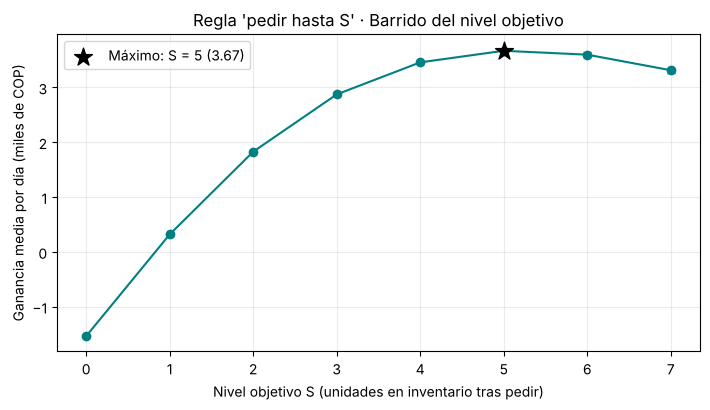

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.errorbar(barrido_S.index, barrido_S["Ganancia/día"], yerr=barrido_S["IC95 ±"], fmt="o-", color="teal", capsize=3)
ax.scatter([S_MEJOR], [barrido_S.loc[S_MEJOR, "Ganancia/día"]], s=180, marker="*", color="black", zorder=3,
           label=f"Máximo: S = {S_MEJOR} ({barrido_S.loc[S_MEJOR, 'Ganancia/día']:.2f})")
ax.set_xlabel("Nivel objetivo S (unidades en inventario tras pedir)")
ax.set_ylabel("Ganancia media por día (miles de COP)")
ax.set_title("Regla 'pedir hasta S' · Barrido del nivel objetivo")
ax.legend()
plt.tight_layout()
guardar_figura("fig2_barrido_S")
plt.show()

**<font color="2ECC71">Interpretación 3.4 (barrido de S):</font>** La ganancia crece con `S` hasta un máximo en **S = 5** (**3,669**) y luego baja: con `S = 7` ya es de 3,314 porque aumenta la merma (de 3,0 % a 8,3 % de lo pedido). Esta es la **mejor regla fija sin información del día**; es la competidora exigente del agente, porque está **ajustada con el simulador**.

In [ ]:
# Referencias: política óptima (Value Iteration) y políticas fijas
politicas["Óptima (Value Iteration)"] = PI_OPT
tabla_ref = pd.DataFrame({nombre: evaluar_politica(pi) for nombre, pi in politicas.items()}).T
GAN_OPT = tabla_ref.loc["Óptima (Value Iteration)", "Ganancia/día"]
GAN_ALE = tabla_ref.loc["Aleatoria", "Ganancia/día"]
GAN_SGL = tabla_ref.loc[f"Mejor S global (S = {S_MEJOR})", "Ganancia/día"]
tabla_ref.round(3)

,Ganancia/día,IC95 ±,Nivel de servicio,Merma (% de lo pedido)
Aleatoria,1.402,0.073,0.799,16.803
Intuitiva (pedir la media del día),3.360,0.044,0.902,4.708
Cuantil crítico por día,2.174,0.012,0.610,0.163
Mejor S global (S = 5),3.669,0.035,0.922,3.042
Óptima (Value Iteration),3.934,0.036,0.956,2.195


**<font color="2ECC71">Interpretación 3.4 (tabla de referencias):</font>**

- **Política óptima (techo):** **3,934** miles de COP por día, con 95,6 % de servicio y 2,2 % de merma.
- **Mejor S global:** **3,669**, es decir **93,3 %** de la ganancia óptima. Es la regla fija que hay que superar.
- **Intuitiva (pedir la media):** **3,360**; se queda corta en los días altos (servicio de 90,2 %).
- **Cuantil crítico de un día:** apenas **2,174**: casi no desecha (0,2 %), pero sufre el peor servicio (61,0 %). Confirma lo anticipado en la sección 1.3: ignorar que el inventario dura varios días lleva a **ordenar de menos**.
- **Aleatoria:** **1,402**, con 16,8 % de merma.

### <font color="2ECC71">3.5 Agentes: Q-Learning y SARSA

>**<font color="BDC3C7">Nota:</font>** Una sola función entrena ambos algoritmos para que **la única diferencia sea la regla de actualización**. Hiperparámetros por defecto: `α = 0,05`, `γ = 0,95`, `ε` decae de **1,0 a 0,05** de forma geométrica durante el **primer 60 %** de los episodios y después se mantiene; la tabla Q se inicia en 0 y los empates se rompen al azar. El fin de los 28 días **no se trata como estado terminal** (el estado no incluye el tiempo restante, así que el problema debe ser estacionario); en la sección 4.4 se comprueba el efecto de esta decisión. Cada 2.000 episodios se evalúa la **política voraz** con 300 episodios de demanda fija para dibujar la curva de aprendizaje.

In [ ]:
def entrenar(algo="q", episodios=EPISODIOS, alpha=0.05, gamma=GAMMA, eps_ini=1.0, eps_fin=0.05,
             frac_explor=0.6, seed=0, cada=2000, terminal_al_truncar=False):
    """Aprendizaje por refuerzo tabular con política epsilon-voraz.

    algo = "q"     -> Q-learning (fuera de política): objetivo r + gamma * max_a' Q(s', a')
    algo = "sarsa" -> SARSA (dentro de la política): objetivo r + gamma * Q(s', a'), con a' la acción realmente elegida
    epsilon decae de forma geométrica de eps_ini a eps_fin durante el primer `frac_explor` de los episodios.
    terminal_al_truncar = True trata el fin del episodio (límite de 28 días) como estado terminal (sin arranque);
    por defecto es False, porque el estado no contiene el tiempo restante.
    Devuelve la tabla Q (N_ESTADOS x NA) y la curva de aprendizaje [(episodio, ganancia/día de la política voraz, epsilon)].
    """
    env = PanaderiaEnv(seed)
    rng = random.Random(seed)
    Q = [[0.0] * NA for _ in range(N_ESTADOS)]
    eps = eps_ini
    decay = (eps_fin / eps_ini) ** (1.0 / (frac_explor * episodios))
    curva = []

    def elegir(s):
        if rng.random() < eps:
            return rng.randrange(NA)                       # explorar
        fila = Q[s]; m = max(fila)
        if fila.count(m) > 1:                              # desempate aleatorio entre acciones igual de buenas
            return rng.choice([i for i, v in enumerate(fila) if v == m])
        return fila.index(m)                               # explotar

    for ep in range(1, episodios + 1):
        s = env.reset(); a = elegir(s); trunc = False
        while not trunc:
            s2, r, term, trunc, _ = env.step(a)
            a2 = elegir(s2)
            if algo == "q":
                futuro = max(Q[s2])
            else:
                futuro = Q[s2][a2]
            objetivo = r if (trunc and terminal_al_truncar) else r + gamma * futuro
            Q[s][a] += alpha * (objetivo - Q[s][a])
            s, a = s2, a2
        eps = max(eps_fin, eps * decay)
        if ep % cada == 0:
            curva.append((ep, evaluar_politica(np.argmax(Q, axis=1), n_ep=300, seed=999)["Ganancia/día"], eps))
    return np.array(Q), curva

### <font color="2ECC71">3.6 Entrenamiento: 100.000 episodios, 5 semillas por algoritmo

>**<font color="BDC3C7">Nota:</font>** Cada algoritmo se entrena **5 veces con semillas distintas** y el mismo presupuesto (100.000 episodios = 2,8 millones de decisiones). Repetir con varias semillas es necesario porque el aprendizaje por refuerzo **depende del azar de la exploración**: una sola corrida podría ser afortunada o desafortunada.

In [ ]:
# Comparación principal: Q-learning y SARSA con el mismo presupuesto y las mismas semillas
resultados = {"q": {}, "sarsa": {}}
t0 = time.time()
for algo in ["q", "sarsa"]:
    for sd in SEMILLAS:
        Q_tab, curva = entrenar(algo, episodios=EPISODIOS, seed=sd)
        resultados[algo][sd] = {"Q": Q_tab, "curva": np.array(curva)}
        print(f"{algo:>5} | semilla {sd} | ganancia final (curva) = {curva[-1][1]:.3f} | {time.time() - t0:5.0f} s acumulados")

np.save(os.path.join(DATA_DIR, "Q_qlearning_semilla0.npy"), resultados["q"][SEMILLAS[0]]["Q"])
np.save(os.path.join(DATA_DIR, "Q_optima_value_iteration.npy"), Q_opt)

    q | semilla 0 | ganancia final (curva) = 3.777 |     7 s acumulados
    q | semilla 1 | ganancia final (curva) = 3.803 |    13 s acumulados
    q | semilla 2 | ganancia final (curva) = 3.853 |    20 s acumulados
    q | semilla 3 | ganancia final (curva) = 3.784 |    26 s acumulados
    q | semilla 4 | ganancia final (curva) = 3.717 |    32 s acumulados
sarsa | semilla 0 | ganancia final (curva) = 3.476 |    38 s acumulados
sarsa | semilla 1 | ganancia final (curva) = 3.521 |    44 s acumulados
sarsa | semilla 2 | ganancia final (curva) = 3.440 |    50 s acumulados
sarsa | semilla 3 | ganancia final (curva) = 3.423 |    55 s acumulados
sarsa | semilla 4 | ganancia final (curva) = 3.535 |    61 s acumulados


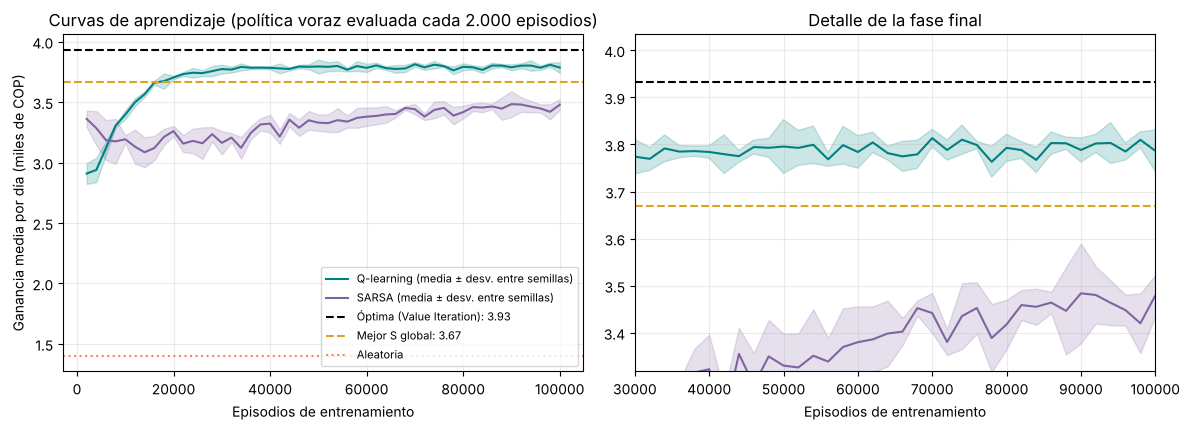

In [ ]:
def banda(ax, algo, color, etiqueta):
    """Dibuja la curva media entre semillas con una banda de ± 1 desviación estándar."""
    x = resultados[algo][SEMILLAS[0]]["curva"][:, 0]
    y = np.array([resultados[algo][sd]["curva"][:, 1] for sd in SEMILLAS])
    ax.plot(x, y.mean(0), color=color, label=etiqueta)
    ax.fill_between(x, y.mean(0) - y.std(0), y.mean(0) + y.std(0), color=color, alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, zoom in zip(axes, [False, True]):
    banda(ax, "q", "teal", "Q-learning (media ± desv. entre semillas)")
    banda(ax, "sarsa", "#8064A2", "SARSA (media ± desv. entre semillas)")
    ax.axhline(GAN_OPT, color="black", ls="--", label=f"Óptima (Value Iteration): {GAN_OPT:.2f}")
    ax.axhline(GAN_SGL, color="goldenrod", ls="--", label=f"Mejor S global: {GAN_SGL:.2f}")
    ax.set_xlabel("Episodios de entrenamiento")
    if zoom:
        ax.set_xlim(EPISODIOS * 0.3, EPISODIOS); ax.set_ylim(GAN_SGL - 0.35, GAN_OPT + 0.1)
        ax.set_title("Detalle de la fase final")
    else:
        ax.axhline(tabla_ref.loc["Aleatoria", "Ganancia/día"], color="salmon", ls=":", label="Aleatoria")
        ax.set_title("Curvas de aprendizaje (política voraz evaluada cada 2.000 episodios)")
        ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("Ganancia media por día (miles de COP)")
plt.tight_layout()
guardar_figura("fig3_curvas_aprendizaje")
plt.show()

**<font color="2ECC71">Interpretación 3.6:</font>**

- **Q-Learning** aprende rápido: supera a la mejor regla fija (3,67) hacia los **16.000 episodios** y se estabiliza cerca de **3,78** a partir de unos 40.000.
- **SARSA** aprende más lento y con más variación: tras 100.000 episodios sigue **por debajo** de la mejor regla fija (cerca de 3,48 en las últimas evaluaciones) y su curva todavía sube.
- **Ninguno alcanza el óptimo (3,93)** con este presupuesto; la brecha restante se analiza en la sección 4.
- **Ruido de la evaluación:** las curvas oscilan algo porque cada punto se mide con solo 300 episodios; la comparación definitiva (sección 4.1) usa 3.000 episodios y una demanda distinta de la del entrenamiento.

---
<a id="seccion-4"></a>
##**<font color="BB86FC">Sección 4 · Análisis de resultados**

**<font color="2ECC71">Objetivo:</font>** Presentar las pruebas realizadas, los resultados, las dificultades encontradas y las conclusiones sobre el desempeño de los algoritmos.

---

### <font color="2ECC71">4.1 Comparación final de políticas

>**<font color="BDC3C7">Nota:</font>** Las políticas aprendidas se evalúan con una **demanda nueva** (semilla 2026, 3.000 episodios) distinta de la usada durante el entrenamiento. Para Q-Learning y SARSA se reporta el **promedio de las 5 semillas** y la desviación estándar entre semillas. La última columna indica qué parte de la brecha entre la política aleatoria y la óptima cubre cada método.

In [ ]:
# Evaluación final con una demanda NUEVA (seed=2026, 3.000 episodios) distinta de la usada al entrenar
EVAL = dict(n_ep=3000, seed=2026)
filas = {}
for nombre, pi in politicas.items():
    filas[nombre] = {**evaluar_politica(pi, **EVAL), "Desv. entre semillas": np.nan}

politicas_rl = {}
for algo, nombre in [("q", "Q-learning"), ("sarsa", "SARSA")]:
    evals = [evaluar_politica(np.argmax(resultados[algo][sd]["Q"], axis=1), **EVAL) for sd in SEMILLAS]
    politicas_rl[nombre] = [np.argmax(resultados[algo][sd]["Q"], axis=1) for sd in SEMILLAS]
    prom = pd.DataFrame(evals).mean()
    filas[nombre] = {**prom.to_dict(), "Desv. entre semillas": pd.DataFrame(evals)["Ganancia/día"].std()}

tabla_final = pd.DataFrame(filas).T
g_opt = tabla_final.loc["Óptima (Value Iteration)", "Ganancia/día"]
g_ale = tabla_final.loc["Aleatoria", "Ganancia/día"]
tabla_final["% de la brecha aleatoria→óptima"] = [pct_optimo(g, g_opt, g_ale) for g in tabla_final["Ganancia/día"]]
orden = ["Aleatoria", "Intuitiva (pedir la media del día)", "Cuantil crítico por día", f"Mejor S global (S = {S_MEJOR})",
         "SARSA", "Q-learning", "Óptima (Value Iteration)"]
tabla_final = tabla_final.loc[orden]
tabla_final.to_csv(os.path.join(DATA_DIR, "resultados_finales.csv"))
tabla_final.round(3)

,Ganancia/día,IC95 ±,Nivel de servicio,Merma (% de lo pedido),Desv. entre semillas,% de la brecha aleatoria→óptima
Aleatoria,1.381,0.043,0.797,16.806,NaN,0.000
Intuitiva (pedir la media del día),3.326,0.026,0.904,4.908,NaN,76.750
Cuantil crítico por día,2.188,0.007,0.614,0.173,NaN,31.853
Mejor S global (S = 5),3.653,0.021,0.924,3.154,NaN,89.694
SARSA,3.457,0.015,0.849,1.269,0.045,81.945
Q-learning,3.759,0.019,0.923,2.147,0.056,93.861
Óptima (Value Iteration),3.914,0.021,0.958,2.251,NaN,100.000


**<font color="2ECC71">Interpretación 4.1:</font>**

- **Q-Learning: 3,759 ± 0,056** (media ± desv. entre semillas), es decir, el **93,9 %** de la brecha entre la política aleatoria y la óptima (3,914). Supera a la mejor regla fija (3,653) con un nivel de servicio equivalente (92,3 % frente a 92,4 %) pero **menos merma** (2,1 % frente a 3,2 %).
- **SARSA: 3,457 ± 0,045**, **82 %** de la brecha: peor que la mejor regla fija. Es más **conservador** (servicio de 84,9 %, merma de 1,3 %): pide menos y deja de vender.
- **Reglas simples:** la intuitiva (3,326) y la del cuantil crítico (2,188) quedan claramente por debajo.
- **Comparación honesta:** la mejora de Q-Learning sobre la mejor regla fija es **modesta** (**+0,106** miles de COP por día, 2,9 %), porque esa regla ya está ajustada con el simulador y solo pierde 0,26 frente al óptimo. El valor del aprendizaje aparece en que **no se le dijo nada del problema** y descubrió por sí solo la estacionalidad.

In [ ]:
# Prueba pareada: ¿la política de Q-learning supera a la mejor regla fija? (misma demanda, 3.000 episodios, por semilla)
def totales_por_episodio(pi, n_ep=3000, seed=2026):
    """Ganancia media por día de cada episodio (para pruebas pareadas)."""
    rng = np.random.default_rng(seed)
    d = rng.integers(0, 7, n_ep); u1 = np.zeros(n_ep, dtype=int); u2 = np.zeros(n_ep, dtype=int); tot = np.zeros(n_ep)
    for _ in range(H):
        D = rng.poisson(DEMANDA_MEDIA[d]); a = pi[(d * NA + u1) * NA + u2]
        v2 = np.minimum(u2, D); r_ = D - v2; v1 = np.minimum(u1, r_); r_ = r_ - v1; v0 = np.minimum(a, r_); falt = r_ - v0
        tot += PRECIO * (v2 + v1 + v0) - COSTO * a - MERMA * (u2 - v2) - FALTANTE * falt
        u2, u1, d = u1 - v1, a - v0, (d + 1) % 7
    return tot / H

ref = totales_por_episodio(politicas[f"Mejor S global (S = {S_MEJOR})"])
filas = []
for nombre in ["Q-learning", "SARSA"]:
    for sd, pi in zip(SEMILLAS, politicas_rl[nombre]):
        dif = totales_por_episodio(pi) - ref
        filas.append({"Algoritmo": nombre, "Semilla": sd, "Diferencia media vs. mejor S": dif.mean(),
                      "IC95 ±": 1.96 * dif.std(ddof=1) / np.sqrt(len(dif))})
pruebas = pd.DataFrame(filas)
pruebas["¿Supera a la mejor S?"] = np.where(pruebas["Diferencia media vs. mejor S"] - pruebas["IC95 ±"] > 0, "Sí", "No")
pruebas.round(3)

,Algoritmo,Semilla,Diferencia media vs. mejor S,IC95 ±,¿Supera a la mejor S?
0,Q-learning,0,0.104,0.010,Sí
1,Q-learning,1,0.136,0.010,Sí
2,Q-learning,2,0.170,0.011,Sí
3,Q-learning,3,0.098,0.012,Sí
4,Q-learning,4,0.020,0.010,Sí
5,SARSA,0,-0.205,0.013,No
6,SARSA,1,-0.153,0.011,No
7,SARSA,2,-0.222,0.013,No
8,SARSA,3,-0.253,0.013,No
9,SARSA,4,-0.149,0.013,No


**<font color="2ECC71">Interpretación de la prueba pareada:</font>** Con la misma demanda, **las 5 semillas de Q-Learning superan a la mejor regla fija** (diferencias de +0,020 a +0,170, todas con intervalo de confianza por encima de 0) y **las 5 de SARSA quedan por debajo** (de −0,149 a −0,253). La ventaja de Q-Learning es consistente en dirección, pero **varía bastante entre semillas**: la semilla 4 apenas supera a la regla fija por 0,020, mientras que la semilla 2 lo hace por 0,170.

### <font color="2ECC71">4.2 ¿Qué aprendió el agente? Comparación con la política óptima

>**<font color="BDC3C7">Nota:</font>** No todos los estados importan: bajo la política óptima solo se visitan con frecuencia unos pocos. Por eso la política aprendida se compara **ponderando cada estado por su frecuencia de visita**. Se calcula la **brecha de valor** (cuánto valor esperado se pierde por decidir como el agente en lugar de como la política óptima) y el **porcentaje de coincidencia de acciones**.

In [ ]:
# Frecuencia con que la política óptima visita cada estado (cadena de Markov exacta, 28 días desde inventario vacío)
P_pi = T[np.arange(N_ESTADOS), PI_OPT]                      # matriz de transición bajo la política óptima
mu = np.zeros(N_ESTADOS)
for d in range(7):
    mu[PanaderiaEnv.codificar(d, 0, 0)] = 1 / 7
visitas = np.zeros(N_ESTADOS)
for _ in range(H):
    visitas += mu / H
    mu = mu @ P_pi
print("Estados visitados con probabilidad > 0,01 %:", int((visitas > 1e-4).sum()), "de", N_ESTADOS)
print("Masa de probabilidad en los 100 estados más visitados:", round(float(np.sort(visitas)[::-1][:100].sum()), 3))

def brecha_y_acuerdo(pi):
    """Brecha de valor (Q*(s,pi*(s)) - Q*(s,pi(s))) y coincidencia de acciones, ponderadas por las visitas de la política óptima."""
    brecha = (V_opt - Q_opt[np.arange(N_ESTADOS), pi])
    return (visitas * brecha).sum(), (visitas * (pi == PI_OPT)).sum()

filas = {}
for nombre, pis in politicas_rl.items():
    vals = np.array([brecha_y_acuerdo(pi) for pi in pis])
    filas[nombre] = {"Brecha de valor media (miles COP)": vals[:, 0].mean(), "Coincidencia con la óptima (ponderada)": vals[:, 1].mean()}
filas["Mejor S global"] = dict(zip(["Brecha de valor media (miles COP)", "Coincidencia con la óptima (ponderada)"],
                                   brecha_y_acuerdo(politicas[f"Mejor S global (S = {S_MEJOR})"])))
pd.DataFrame(filas).T.round(3)

Estados visitados con probabilidad > 0,01 %: 133 de 448
Masa de probabilidad en los 100 estados más visitados: 0.98


,Brecha de valor media (miles COP),Coincidencia con la óptima (ponderada)
Q-learning,0.160,0.355
SARSA,0.504,0.158
Mejor S global,0.274,0.186


**<font color="2ECC71">Interpretación 4.2 (cobertura y brecha de valor):</font>**

- **Pocos estados dominan:** solo **133 de 448** estados se visitan con probabilidad mayor a 0,01 % y los **100 más frecuentes concentran el 98 %** de las visitas. Por eso las celdas poco visitadas de la tabla Q casi no afectan el resultado.
- **Q-Learning pierde en promedio 0,160** miles de COP por decisión frente al óptimo, **menos que la mejor regla fija (0,274)** y mucho menos que SARSA (0,504).
- **La coincidencia exacta de acciones es baja** (**35,5 %** para Q-Learning, 15,8 % para SARSA), pero engaña: muchas acciones distintas valen casi lo mismo. Por eso la **brecha de valor** es la medida más informativa.

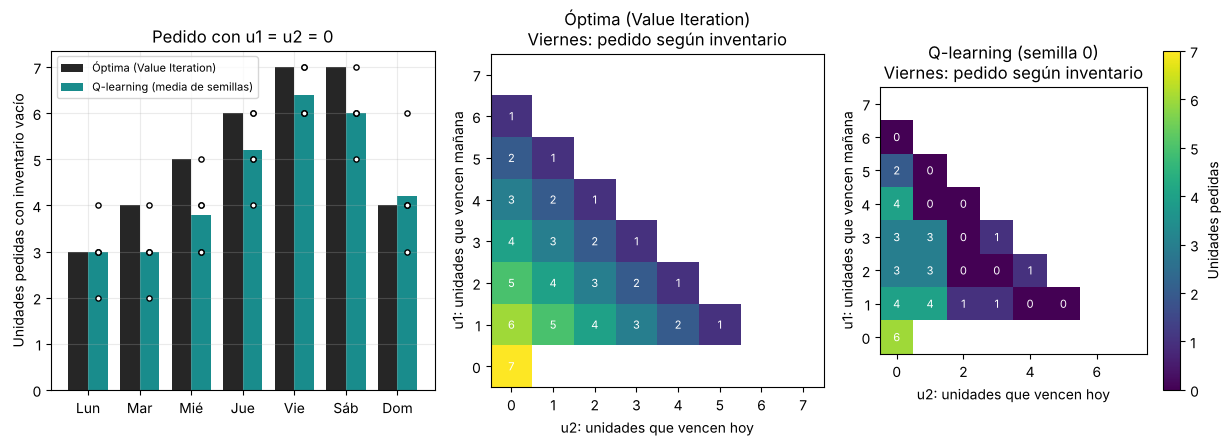

In [ ]:
# ¿Qué aprendió el agente? Pedido con inventario vacío cada día y mapa de decisiones del viernes
pedido_vacio = lambda pi: pi.reshape(7, NA, NA)[:, 0, 0]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.15, 1, 1]})

ax = axes[0]
x = np.arange(7); w = 0.38
ax.bar(x - w / 2, pedido_vacio(PI_OPT), w, color="black", alpha=0.85, label="Óptima (Value Iteration)")
pq = np.array([pedido_vacio(pi) for pi in politicas_rl["Q-learning"]])
ax.bar(x + w / 2, pq.mean(0), w, color="teal", alpha=0.9, label="Q-learning (media de semillas)")
ax.scatter(np.repeat(x, len(SEMILLAS)) + w / 2, pq.T.ravel(), s=14, color="white", edgecolor="black", zorder=3)
ax.set_xticks(x); ax.set_xticklabels([d[:3] for d in DIAS])
ax.set_ylabel("Unidades pedidas con inventario vacío")
ax.set_title("Pedido con u1 = u2 = 0")
ax.legend(fontsize=8)

dia_mapa = 4   # viernes
for ax, (titulo, pi) in zip(axes[1:], [("Óptima (Value Iteration)", PI_OPT), ("Q-learning (semilla 0)", politicas_rl["Q-learning"][0])]):
    M = pi.reshape(7, NA, NA)[dia_mapa].astype(float)
    V = visitas.reshape(7, NA, NA)[dia_mapa]
    M[V < 1e-5] = np.nan                                    # se ocultan los estados prácticamente inalcanzables
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=CAP, origin="lower")
    for i in range(NA):
        for j in range(NA):
            if not np.isnan(M[i, j]):
                ax.text(j, i, int(M[i, j]), ha="center", va="center", color="white", fontsize=8)
    ax.set_xlabel("u2: unidades que vencen hoy"); ax.set_ylabel("u1: unidades que vencen mañana")
    ax.set_title(f"{titulo}\nViernes: pedido según inventario"); ax.grid(False)
plt.colorbar(im, ax=axes[2], label="Unidades pedidas")
plt.tight_layout()
guardar_figura("fig4_politica_aprendida")
plt.show()

**<font color="2ECC71">Interpretación de la figura 4.2:</font>**

- **Panel izquierdo (inventario vacío):** Q-Learning reproduce el **patrón semanal** de la política óptima (pedir poco a inicio de semana y más hacia el jueves, viernes y sábado), pero con **menos unidades** en promedio los días miércoles a viernes y con dispersión entre semillas (puntos blancos). Aprendió la forma, no los valores exactos.
- **Paneles derechos (mapa del viernes):** la política óptima es regular: **completa hasta 7 unidades en total** (si hay `u1 + u2` en inventario, pide `7 − u1 − u2`). Q-Learning acierta en la zona de poco inventario y se desvía en los estados con más stock, donde pide cero unidades. Es un comportamiento razonable pero **no óptimo**, en estados que se visitan poco y donde el agente tiene menos experiencia.

In [ ]:
# Dos semanas con la política aprendida (Q-learning, semilla 0) frente a la mejor regla fija, con la misma demanda
def simular_traza(pi, dias=14, dia_ini=0, seed=11):
    envt = PanaderiaEnv(seed); s = envt.reset(dia=dia_ini); filas = []
    for _ in range(dias):
        d, u1, u2 = envt.decodificar(s)
        a = int(pi[s]); s, r, term, trunc, info = envt.step(a)
        filas.append({"Día": DIAS[d][:3], "u1": u1, "u2": u2, "Pedido": a, "Demanda": info["demanda"], "Ventas": info["ventas"],
                      "Faltante": info["faltante"], "Merma": info["merma"], "Ganancia": r})
    return pd.DataFrame(filas)

tr_q = simular_traza(politicas_rl["Q-learning"][0])
tr_s = simular_traza(politicas[f"Mejor S global (S = {S_MEJOR})"])
print(f"Ganancia en 14 días | Q-learning: {tr_q['Ganancia'].sum():.1f} | Mejor S global: {tr_s['Ganancia'].sum():.1f}"
      f" | faltantes: {tr_q['Faltante'].sum()} vs {tr_s['Faltante'].sum()} | merma: {tr_q['Merma'].sum()} vs {tr_s['Merma'].sum()}")
tr_q

Ganancia en 14 días | Q-learning: 52.5 | Mejor S global: 42.0 | faltantes: 3 vs 4 | merma: 0 vs 2


,Día,u1,u2,Pedido,Demanda,Ventas,Faltante,Merma,Ganancia
0,Lun,0,0,3,0,0,0,0,-7.5
1,Mar,3,0,0,2,2,0,0,8.0
2,Mié,0,1,4,2,2,0,0,-2.0
3,Jue,3,0,0,3,3,0,0,12.0
4,Vie,0,0,6,3,3,0,0,-3.0
5,Sáb,3,0,3,8,6,2,0,15.5
6,Dom,0,0,3,2,2,0,0,0.5
7,Lun,1,0,1,2,2,0,0,5.5
8,Mar,0,0,3,1,1,0,0,-3.5
9,Mié,2,0,2,1,1,0,0,-1.0


**<font color="2ECC71">Interpretación de la traza de 14 días:</font>** Con la misma demanda, la política de Q-Learning gana **52,5** frente a **42,0** de la mejor regla fija, con **menos faltantes (3 frente a 4)** y **sin merma (0 frente a 2)**. Se observa cómo **no pide nada** el martes y el jueves cuando le sobra inventario del día anterior y pide más (6 unidades) el viernes antes del sábado. Es **una sola trayectoria de 14 días**, útil para ilustrar el comportamiento, no como evidencia estadística (esa es la tabla 4.1).

### <font color="2ECC71">4.3 Sensibilidad a los hiperparámetros

>**<font color="BDC3C7">Nota:</font>** Se varía **un hiperparámetro a la vez** (los demás en su valor por defecto) y se entrena Q-Learning con **50.000 episodios y 3 semillas** por configuración. Se mide la ganancia diaria de la política voraz final con una demanda nueva. Se prueban la tasa de aprendizaje `α`, el factor de descuento `γ`, la exploración residual `ε` final y la duración del decaimiento de `ε`.

In [ ]:
def barrer(nombre, valores, **fijos):
    """Entrena Q-learning para cada valor de un hiperparámetro y mide la política voraz final (demanda nueva)."""
    filas = []
    for v in valores:
        gs = []
        for sd in SEMILLAS_BARRIDO:
            kw = dict(fijos); kw.update({nombre: v})
            Q_tab, _ = entrenar("q", episodios=EPISODIOS_BARRIDO, seed=sd, cada=EPISODIOS_BARRIDO, **kw)
            gs.append(evaluar_politica(np.argmax(Q_tab, axis=1), n_ep=2000, seed=2026)["Ganancia/día"])
        filas.append({"Valor": v, "Ganancia/día (media)": np.mean(gs), "Desv. entre semillas": np.std(gs, ddof=1), "Mínimo": np.min(gs)})
        print(f"  {nombre} = {v}: {np.mean(gs):.3f} ± {np.std(gs, ddof=1):.3f}", flush=True)
    return pd.DataFrame(filas).set_index("Valor")

In [ ]:
print("Tasa de aprendizaje alpha:")
sens_alpha = barrer("alpha", [0.01, 0.05, 0.1, 0.3, 0.5])
sens_alpha.round(3)

Tasa de aprendizaje alpha:
  alpha = 0.01: 3.115 ± 0.128
  alpha = 0.05: 3.734 ± 0.030
  alpha = 0.1: 3.706 ± 0.028
  alpha = 0.3: 3.530 ± 0.043
  alpha = 0.5: 3.445 ± 0.129


,Ganancia/día (media),Desv. entre semillas,Mínimo
Valor,,,
0.01,3.115,0.128,2.990
0.05,3.734,0.030,3.714
0.10,3.706,0.028,3.680
0.30,3.530,0.043,3.497
0.50,3.445,0.129,3.298


In [ ]:
print("Factor de descuento gamma:")
sens_gamma = barrer("gamma", [0.0, 0.5, 0.9, 0.95, 0.99])
sens_gamma.round(3)

Factor de descuento gamma:
  gamma = 0.0: 2.135 ± 0.095
  gamma = 0.5: 3.055 ± 0.170
  gamma = 0.9: 3.706 ± 0.029
  gamma = 0.95: 3.734 ± 0.030
  gamma = 0.99: 3.337 ± 0.081


,Ganancia/día (media),Desv. entre semillas,Mínimo
Valor,,,
0.00,2.135,0.095,2.035
0.50,3.055,0.170,2.868
0.90,3.706,0.029,3.682
0.95,3.734,0.030,3.714
0.99,3.337,0.081,3.257


In [ ]:
print("Epsilon final (exploración residual):")
sens_eps = barrer("eps_fin", [0.0, 0.01, 0.05, 0.2, 0.5])
print("Fracción del entrenamiento con exploración decreciente:")
sens_frac = barrer("frac_explor", [0.1, 0.3, 0.6, 0.9])
pd.concat({"epsilon final": sens_eps, "fracción de decaimiento": sens_frac}).round(3)

Epsilon final (exploración residual):
  eps_fin = 0.0: 2.325 ± 0.292
  eps_fin = 0.01: 3.626 ± 0.015
  eps_fin = 0.05: 3.734 ± 0.030
  eps_fin = 0.2: 3.761 ± 0.009
  eps_fin = 0.5: 3.757 ± 0.044
Fracción del entrenamiento con exploración decreciente:
  frac_explor = 0.1: 3.681 ± 0.029
  frac_explor = 0.3: 3.695 ± 0.060
  frac_explor = 0.6: 3.734 ± 0.030
  frac_explor = 0.9: 3.711 ± 0.017


Ganancia/día (media)  Desv. entre semillas  Mínimo
                        Valor                                                    
epsilon final           0.00                  2.325                 0.292   1.994
                        0.01                  3.626                 0.015   3.613
                        0.05                  3.734                 0.030   3.714
                        0.20                  3.761                 0.009   3.751
                        0.50                  3.757                 0.044   3.717
fracción de decaimiento 0.10                  3.681                 0.029   3.648
                        0.30                  3.695                 0.060   3.627
                        0.60                  3.734                 0.030   3.714
                        0.90                  3.711                 0.017   3.693

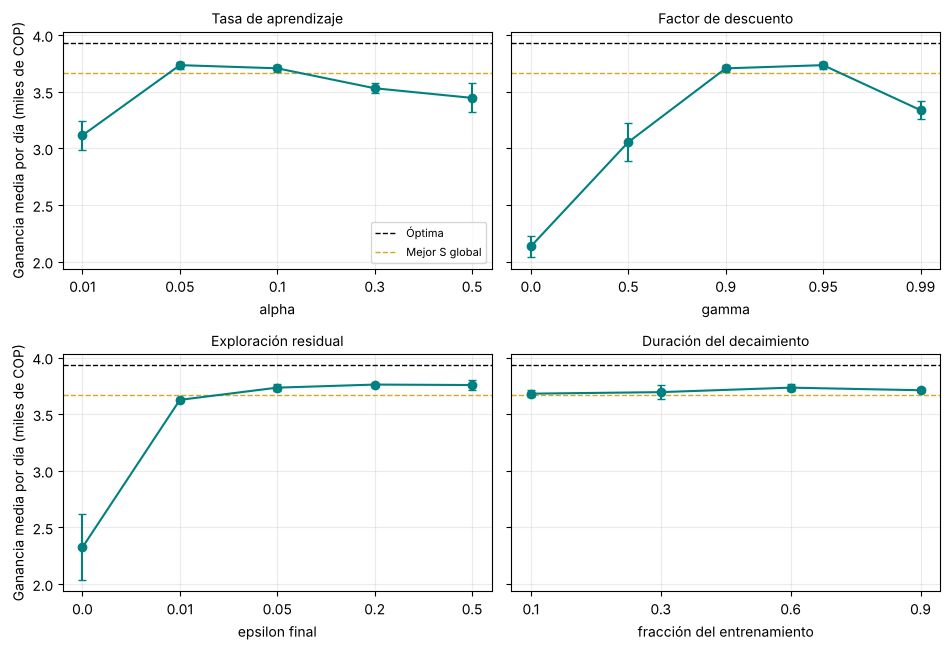

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(9.6, 6.6), sharey=True)
for ax, (df, titulo, xlab) in zip(axes.ravel(), [(sens_alpha, "Tasa de aprendizaje", "alpha"),
                                          (sens_gamma, "Factor de descuento", "gamma"),
                                          (sens_eps, "Exploración residual", "epsilon final"),
                                          (sens_frac, "Duración del decaimiento", "fracción del entrenamiento")]):
    ax.errorbar(range(len(df)), df["Ganancia/día (media)"], yerr=df["Desv. entre semillas"], fmt="o-", color="teal", capsize=3)
    ax.axhline(GAN_OPT, color="black", ls="--", lw=1, label="Óptima")
    ax.axhline(GAN_SGL, color="goldenrod", ls="--", lw=1, label="Mejor S global")
    ax.set_xticks(range(len(df))); ax.set_xticklabels([str(v) for v in df.index])
    ax.set_xlabel(xlab); ax.set_title(titulo, fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("Ganancia media por día (miles de COP)")
axes[0, 0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
guardar_figura("fig5_sensibilidad_hiperparametros")
plt.show()

**<font color="2ECC71">Interpretación 4.3:</font>**

- **Tasa de aprendizaje α:** el mejor valor es **0,05** (3,734 ± 0,030) y 0,1 es casi igual (3,706). Con **0,01** el aprendizaje es demasiado lento para 50.000 episodios (3,115) y con **0,3 y 0,5** las actualizaciones son tan grandes que la tabla fluctúa con cada demanda aleatoria (3,530 y 3,445, este último con mucha variación entre semillas).
- **Factor de descuento γ:** con **γ = 0** (el agente solo mira la ganancia del día) la política es mala (**2,135**): no aprende a **anticipar** la demanda del fin de semana. Mejora con γ = 0,5 (3,055) y llega a su mejor valor en **0,9 a 0,95** (3,706 y 3,734). Con **0,99** baja otra vez (**3,337**); lo más probable es que, al contar un horizonte tan largo, los valores tarden mucho más en estabilizarse con el mismo presupuesto.
- **Exploración residual ε final:** sin exploración al final (**ε = 0**) el aprendizaje queda atascado en una política mediocre (2,325, con variación enorme entre semillas, ±0,292). Con **0,01** ya se alcanza 3,626 y con **0,05, 0,2 y 0,5** se llega a 3,734, 3,761 y 3,757. Es un hallazgo útil: **una exploración alta mantenida (0,2) no perjudica** la política voraz final y hasta da el valor más alto y estable (±0,009), porque ayuda a cubrir más estados.
- **Duración del decaimiento:** casi no influye (3,681 a 3,734); la configuración por defecto (60 %) es la mejor, con diferencias pequeñas frente a la variación entre semillas.
- **Conclusión práctica:** el aprendizaje es **robusto** en un rango amplio de `α` (0,05 a 0,1), `γ` (0,9 a 0,95) y `ε` final (0,05 a 0,5), y **frágil** cuando `γ` es pequeño o no hay exploración.

### <font color="2ECC71">4.4 Dificultad detectada: tratamiento del fin del episodio

>**<font color="BDC3C7">Nota:</font>** Los episodios duran 28 días por conveniencia de la simulación, pero la tienda opera de forma continua. Si el último paso se trata como **terminal** (sin valor futuro), el agente aprende que "después del día 28 no hay nada", algo que **no puede distinguir** porque el estado no incluye cuántos días quedan: el mismo estado tendría valores contradictorios. Se compara con el tratamiento correcto (continuar el cálculo del valor futuro al truncar).

In [ ]:
# Dificultad detectada: ¿qué pasa si el fin del episodio (día 28) se trata como estado terminal?
filas = []
for etiqueta, flag in [("Con arranque al truncar (usado)", False), ("Terminal al truncar", True)]:
    gs = []
    for sd in SEMILLAS_BARRIDO:
        Q_tab, _ = entrenar("q", episodios=EPISODIOS_BARRIDO, seed=sd, cada=EPISODIOS_BARRIDO, terminal_al_truncar=flag)
        gs.append(evaluar_politica(np.argmax(Q_tab, axis=1), n_ep=2000, seed=2026)["Ganancia/día"])
    filas.append({"Tratamiento del día 28": etiqueta, "Ganancia/día (media)": np.mean(gs), "Desv. entre semillas": np.std(gs, ddof=1)})
pd.DataFrame(filas).set_index("Tratamiento del día 28").round(3)

,Ganancia/día (media),Desv. entre semillas
Tratamiento del día 28,,
Con arranque al truncar (usado),3.734,0.030
Terminal al truncar,3.542,0.038


**<font color="2ECC71">Interpretación 4.4:</font>** Tratar el día 28 como terminal **reduce la ganancia de 3,734 a 3,542** (menos 5,1 %) con el mismo presupuesto. Es un ejemplo de que un **detalle de implementación** (diferenciar *terminar* de *truncar*) puede cambiar el resultado tanto como un hiperparámetro. **Cautela:** al ejecutar el cuaderno con `RAPIDO = True` (10.000 episodios y 2 semillas) el orden se invierte (3,189 con arranque frente a 3,473 como terminal), de modo que la ventaja del tratamiento correcto se observa con entrenamientos más largos y con solo 3 semillas no es una conclusión definitiva.

### <font color="2ECC71">4.5 Dificultades encontradas

>**<font color="BDC3C7">1. Diseño del problema:</font>** una primera versión (demanda alta y capacidad de 8 unidades) resultó **demasiado fácil**: la regla fija "pedir hasta el máximo" quedaba casi igual a la óptima y el aprendizaje no aportaba nada. Se ajustaron costos y demanda hasta que **la política óptima fuera claramente mejor que las reglas simples**.

>**<font color="BDC3C7">2. Fin del episodio:</font>** tratar el día 28 como estado terminal degradaba el aprendizaje (sección 4.4). Se usó el valor futuro también en el último paso (con 50.000 episodios es mejor; con 10.000 no, ver cautela en 4.4).

>**<font color="BDC3C7">3. Estados poco visitados:</font>** solo 133 de 448 estados aparecen con frecuencia; en el resto la tabla Q tiene pocas observaciones y la política difiere de la óptima. Sin exploración final (ε = 0) el agente se atascó (sección 4.3).

>**<font color="BDC3C7">4. Variabilidad entre semillas:</font>** el resultado de Q-Learning varía de 3,717 a 3,853 según la semilla, por lo que **una sola corrida no basta** y se reportan 5 semillas.

>**<font color="BDC3C7">5. Métrica de comparación:</font>** la coincidencia exacta de acciones con la política óptima es baja aunque el valor sea casi igual; se usó la **brecha de valor ponderada** como medida principal.

>**<font color="BDC3C7">6. Limitaciones del enfoque:</font>** (a) la **tabla Q no generaliza**: no aprovecha que estados parecidos deberían tener decisiones parecidas, y por eso necesita muchos episodios; (b) el problema es **simulado**, con una demanda Poisson independiente día a día; (c) no se modelaron plazo de entrega, varios productos ni precios variables; (d) la comparación con la regla fija es a favor de la regla, porque se ajustó con el mismo simulador; (e) los resultados dependen de los **supuestos de costos**.

### <font color="2ECC71">4.6 Preguntas de análisis

>**<font color="BDC3C7">1. ¿Qué aprendió el agente?:</font>**
A pedir **más hacia el fin de semana y menos a inicio de semana**, y a **ajustar el pedido al inventario que ya tiene** (no pedir cuando le sobra producto del día anterior). Reproduce el patrón semanal de la política óptima, pero con valores algo más bajos en los días de mayor demanda.

>**<font color="BDC3C7">2. ¿Qué tan cerca llegó de la política óptima?:</font>**
Cubre el **93,9 %** de la brecha entre la política aleatoria y la óptima: gana **3,759** frente a **3,914** miles de COP por día (**96,0 %** del valor óptimo).

>**<font color="BDC3C7">3. ¿Valió la pena aprender frente a una regla simple?:</font>**
Frente a la **mejor regla fija** ajustada, Q-Learning mejora **0,106** por día (2,9 %), con menos merma pero la misma cobertura de la demanda. La ganancia es **real y consistente en las 5 semillas**, aunque modesta. Frente a reglas no ajustadas (intuitiva o cuantil crítico) la ventaja es grande (+13 % y +72 %).

>**<font color="BDC3C7">4. ¿Por qué Q-Learning superó a SARSA?:</font>**
Q-Learning aprende el valor de la **política voraz** aunque explore; SARSA aprende el valor de la política **con exploración** (5 % de pedidos al azar al final), que penaliza pedir de más y lo vuelve **conservador** (servicio de 84,9 %). Además SARSA seguía mejorando tras 100.000 episodios, así que con más entrenamiento la diferencia podría reducirse; no se comprobó.

>**<font color="BDC3C7">5. ¿Qué papel cumple la exploración?:</font>**
Es **indispensable**: sin exploración final (ε = 0) el resultado cae a 2,325 con mucha variación. Una exploración residual mayor (0,2) no dañó el resultado.

>**<font color="BDC3C7">6. ¿Qué papel cumple el factor de descuento?:</font>**
Hace que el agente **anticipe**: con γ = 0 no aprende a acumular inventario para el fin de semana (2,135) y con 0,9 a 0,95 sí (3,706 a 3,734).

>**<font color="BDC3C7">7. ¿Qué limitaciones tiene el enfoque tabular?:</font>**
No generaliza entre estados y crece de forma explosiva con más variables (otros productos, edades, plazos). Para problemas más grandes se necesitaría **aproximación de funciones** (por ejemplo, redes neuronales profundas).

---

### <font color="2ECC71">4.7 Resumen de resultados exportados

>**<font color="BDC3C7">Nota:</font>** Se guardan en `/data` los resultados finales y los barridos de hiperparámetros en formato CSV, junto con la tabla Q aprendida y la óptima, para que el informe y los resultados sean reproducibles.

In [ ]:
# Tabla resumen para el informe (valores de todas las secciones)
resumen = tabla_final[["Ganancia/día", "Nivel de servicio", "Merma (% de lo pedido)", "% de la brecha aleatoria→óptima"]].copy()
resumen.to_csv(os.path.join(DATA_DIR, "resumen_para_informe.csv"))
for nombre, df in [("alpha", sens_alpha), ("gamma", sens_gamma), ("eps_fin", sens_eps), ("frac_explor", sens_frac)]:
    df.to_csv(os.path.join(DATA_DIR, f"sensibilidad_{nombre}.csv"))
resumen.round(3)

,Ganancia/día,Nivel de servicio,Merma (% de lo pedido),% de la brecha aleatoria→óptima
Aleatoria,1.381,0.797,16.806,0.000
Intuitiva (pedir la media del día),3.326,0.904,4.908,76.750
Cuantil crítico por día,2.188,0.614,0.173,31.853
Mejor S global (S = 5),3.653,0.924,3.154,89.694
SARSA,3.457,0.849,1.269,81.945
Q-learning,3.759,0.923,2.147,93.861
Óptima (Value Iteration),3.914,0.958,2.251,100.000


---
<a id="seccion-5"></a>
##**<font color="BB86FC">Sección 5 · Conclusiones**

<font color=#FFFFFF>

1. **Formulación:** la reposición de un producto perecedero se modeló como un MDP de **448 estados y 8 acciones**, con estado `(día, unidades que vencen mañana, unidades que vencen hoy)`, acción de pedido y recompensa de ganancia diaria. La solución exacta (Value Iteration) permitió **medir** el aprendizaje, no solo observarlo.
2. **Q-Learning funciona:** con 100.000 episodios llega a **3,759 ± 0,056** miles de COP por día, el **93,9 %** de la brecha entre la política aleatoria y la óptima (3,914), y **supera a la mejor regla fija** en las 5 semillas. La mejora es **modesta** (+0,106 por día, 2,9 %) porque esa regla ya estaba ajustada con el simulador.
3. **SARSA rinde menos en este caso** (3,457 ± 0,045): aprende el valor de la política con exploración, resulta conservador (servicio de 84,9 %) y seguía mejorando al terminar el entrenamiento.
4. **El agente aprendió la estacionalidad** sin que se le dijera: pide más hacia el fin de semana y menos al inicio, pero queda por debajo de la política óptima en los días de mayor demanda y en estados poco visitados.
5. **Hiperparámetros:** el aprendizaje es robusto con `α` entre 0,05 y 0,1, `γ` entre 0,9 y 0,95 y `ε` final entre 0,05 y 0,5; es frágil con `γ = 0` (2,135) y sin exploración (2,325).
6. **Detalle de implementación:** con 50.000 episodios, tratar el límite de 28 días como estado terminal baja la ganancia de 3,734 a 3,542; con presupuestos más cortos el efecto se invierte, así que es un punto que debe verificarse y no una regla general (**truncar no es terminar**).
7. **Limitaciones:** el problema es **simulado** con supuestos de costos y demanda, la tabla Q **no generaliza** y la comparación se hizo con una sola configuración de costos. Como trabajo futuro: calibrar con datos reales de ventas, añadir plazo de entrega y varios productos, y probar **Deep Q-Network** o **Monte Carlo con aproximación de funciones**.

---
<a id="seccion-6"></a>
##**<font color="BB86FC">Sección 6 · Referencias**

- Bellman, R. (1957). *Dynamic programming*. Princeton University Press.
- Brockman, G., Cheung, V., Pettersson, L., Schneider, J., Schulman, J., Tang, J., & Zaremba, W. (2016). *OpenAI Gym*. arXiv. https://doi.org/10.48550/arXiv.1606.01540
- Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357-362. https://doi.org/10.1038/s41586-020-2649-2
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55
- Nahmias, S. (1982). Perishable inventory theory: A review. *Operations Research, 30*(4), 680-708. https://doi.org/10.1287/opre.30.4.680
- Puterman, M. L. (1994). *Markov decision processes: Discrete stochastic dynamic programming*. Wiley.
- Rummery, G. A., & Niranjan, M. (1994). *On-line Q-learning using connectionist systems* (Technical Report CUED/F-INFENG/TR 166). Cambridge University Engineering Department.
- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement learning: An introduction* (2.ª ed.). MIT Press.
- Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261-272. https://doi.org/10.1038/s41592-019-0686-2
- Watkins, C. J. C. H., & Dayan, P. (1992). Q-learning. *Machine Learning, 8*(3-4), 279-292. https://doi.org/10.1007/BF00992698
- Universidad de Cundinamarca · CADI Introducción a Machine Learning (2026). *Tarea – Reinforcement Learning (Semana 14)*.